# DataSentinel: Agentic Dataset Trust & Poisoning Detection
## Milestone 1: Tabular Baseline & Dataset Ingestion

This notebook implements the baseline pipeline for the **UCI Credit Card Default** dataset:
- Dataset loading & inspection
- Cleaning & target normalization
- Stratified Train/Test split
- Baseline 1: Logistic Regression with StandardScaler
- Baseline 2: Random Forest Classifier
- Evaluation metrics (Accuracy, Precision, Recall, F1, ROC-AUC)
- Model & prediction persistence for DataSentinel's label integrity detector

### 1. Import Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### 2. Download / Load Dataset

In [2]:
# Check for local dataset first, otherwise fetch from ucimlrepo
raw_path_primary = os.path.join("..", "data", "raw", "default of credit card clients.xls")
raw_path_alt = os.path.join("..", "data", "raw", "Datset of credit card Clientsts.xls")

if os.path.exists(raw_path_primary) or os.path.exists(raw_path_alt):
    file_to_load = raw_path_primary if os.path.exists(raw_path_primary) else raw_path_alt
    print(f"Loading local dataset from: {file_to_load}")
    df_raw = pd.read_excel(file_to_load, header=1)
    target_col = [c for c in df_raw.columns if "default" in c.lower()][0]
    X = df_raw.drop(columns=[target_col])
    y = df_raw[[target_col]]
else:
    print("Loading dataset from ucimlrepo...")
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=350)
    X = dataset.data.features
    y = dataset.data.targets

print("Dataset loaded successfully")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Loading local dataset from: ..\data\raw\default of credit card clients.xls


Dataset loaded successfully
Features shape: (30000, 24)
Target shape: (30000, 1)


### 3. Inspect the Dataset

In [3]:
print(X.head())
print("\nTarget:")
print(y.head())

print("\nColumns:")
print(X.columns.tolist())

print("\nData types:")
print(X.dtypes)

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nTarget distribution:")
print(y.iloc[:, 0].value_counts())

   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1      20000    2          2         1   24      2      2     -1     -1   
1   2     120000    2          2         2   26     -1      2      0      0   
2   3      90000    2          2         2   34      0      0      0      0   
3   4      50000    2          2         1   37      0      0      0      0   
4   5      50000    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT3  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  \
0  ...        689          0          0          0         0       689   
1  ...       2682       3272       3455       3261         0      1000   
2  ...      13559      14331      14948      15549      1518      1500   
3  ...      49291      28314      28959      29547      2000      2019   
4  ...      35835      20940      19146      19131      2000     36681   

   PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6  
0         0         0         0     

### 4. Clean the Target & Features

In [4]:
# Make the target a simple 1-D array
y = y.iloc[:, 0].astype(int)

# Remove an ID column if the import contains one
if "ID" in X.columns:
    X = X.drop(columns=["ID"])

print("Final feature shape:", X.shape)

Final feature shape: (30000, 23)


### 5. Train / Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24000
Testing samples: 6000


### 6. Build Baseline Model 1 — Logistic Regression

In [6]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

### 7. Evaluate Logistic Regression

In [7]:
print("Logistic Regression")
print("-" * 30)

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr))

print("Recall:",
      recall_score(y_test, y_pred_lr))

print("F1 Score:",
      f1_score(y_test, y_pred_lr))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression
------------------------------
Accuracy: 0.6796666666666666
Precision: 0.36724676483712626
Recall: 0.6201959306706858
F1 Score: 0.461322869955157
ROC-AUC: 0.7081149369197677

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.70      0.77      4673
           1       0.37      0.62      0.46      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.70      6000



### 8. Build Baseline Model 2 — Random Forest

In [8]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

### 9. Evaluate Random Forest

In [9]:
print("Random Forest")
print("-" * 30)

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf))

print("Recall:",
      recall_score(y_test, y_pred_rf))

print("F1 Score:",
      f1_score(y_test, y_pred_rf))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest
------------------------------
Accuracy: 0.8145
Precision: 0.6486111111111111
Recall: 0.3519216277317257
F1 Score: 0.4562774792379091
ROC-AUC: 0.7578613436291891

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.65      0.35      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.80      0.81      0.79      6000



### 10. Compare the Two Models

In [10]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Logistic Regression  0.679667   0.367247  0.620196  0.461323  0.708115
1        Random Forest  0.814500   0.648611  0.351922  0.456277  0.757861


### 11. Save the Baseline Model

In [11]:
os.makedirs("../models", exist_ok=True)
joblib.dump(
    rf_model,
    "../models/baseline_random_forest.pkl"
)

print("Baseline model saved.")

Baseline model saved.


### 12. Save Predictions for Evidence Pipeline

In [12]:
os.makedirs("../experiments", exist_ok=True)
baseline_predictions = pd.DataFrame({
    "actual": y_test.values,
    "prediction": y_pred_rf,
    "probability_default": y_prob_rf
})

baseline_predictions.to_csv(
    "../experiments/baseline_predictions.csv",
    index=False
)

print(baseline_predictions.head())

   actual  prediction  probability_default
0       0           0             0.086667
1       0           0             0.150000
2       0           0             0.196667
3       1           0             0.123333
4       0           0             0.020000


### 13. Basic Visualization: Confusion Matrix

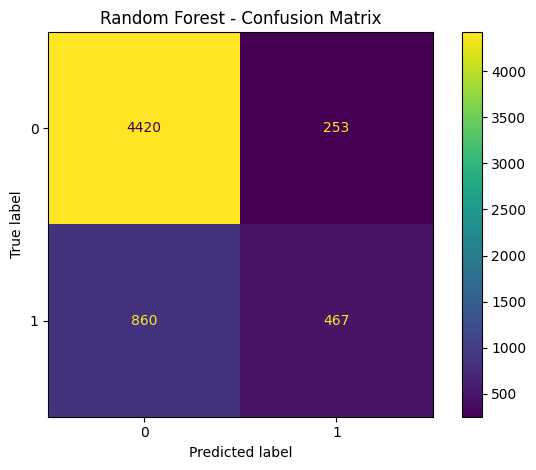

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig("../experiments/baseline_rf_confusion_matrix.png", dpi=300)
plt.show()